In [1]:
# ---------- STEP 1 (FIXED): Load, check dates, clean ----------
import pandas as pd
import numpy as np
from google.colab import files

# 1. Upload CSV
file_name = "/content/HHS_Unaccompanied_Alien_Children_Program.csv"
raw = pd.read_csv(file_name)
print("Raw shape:", raw.shape)

# 2. Rename columns
def rename_col(c):
    c_low = c.lower()
    if 'date' in c_low: return 'date'
    if 'apprehended' in c_low: return 'apprehended'
    if 'in cbp' in c_low: return 'cbp_custody'
    if 'transferred' in c_low: return 'transferred'
    if 'in hhs' in c_low: return 'hhs_care'
    if 'discharged' in c_low: return 'discharged'
    return c

df = raw.copy()
df.columns = [rename_col(c) for c in df.columns]

# 3. LOOK AT THE RAW DATES FIRST
print("\nFirst 10 raw dates:", df['date'].head(10).tolist())
print("Last 10 raw dates :", df['date'].tail(10).tolist())
print("Blank dates:", df['date'].isnull().sum())

# 4. Try both date styles and keep the better one
d1 = pd.to_datetime(df['date'], errors='coerce')
d2 = pd.to_datetime(df['date'], errors='coerce', dayfirst=True)
print("\nUnparsed -> default:", d1.isnull().sum(), "| dayfirst:", d2.isnull().sum())
print("Unique dates -> default:", d1.nunique(), "| dayfirst:", d2.nunique())

df['date'] = d1 if d1.nunique() >= d2.nunique() else d2

# 5. Convert numeric columns
num_cols = ['apprehended', 'cbp_custody', 'transferred', 'hhs_care', 'discharged']
for col in num_cols:
    df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', '').str.strip(), errors='coerce')

# 6. Remove rows with no date only (do NOT drop duplicates yet, just count them)
before = len(df)
df = df.dropna(subset=['date']).sort_values('date').reset_index(drop=True)
print("\nRows removed (no date):", before - len(df))
print("Duplicate dates found:", df['date'].duplicated().sum())

# 7. Show a few duplicate examples so we can decide what to do
dups = df[df['date'].duplicated(keep=False)]
print("\nSample duplicate rows:")
display(dups.head(10))

# 8. Final summary
print("\nDate range:", df['date'].min().date(), "to", df['date'].max().date())
print("Rows now:", len(df))
print("Missing values:\n", df.isnull().sum())
display(df.head())

Raw shape: (1170, 6)

First 10 raw dates: ['December 21, 2025', 'December 18, 2025', 'December 17, 2025', 'December 16, 2025', 'December 15, 2025', 'December 14, 2025', 'December 11, 2025', 'December 10, 2025', 'December 09, 2025', 'December 08, 2025']
Last 10 raw dates : [nan, nan, nan, nan, nan, nan, nan, nan, nan, nan]
Blank dates: 450

Unparsed -> default: 450 | dayfirst: 450
Unique dates -> default: 720 | dayfirst: 720

Rows removed (no date): 450
Duplicate dates found: 0

Sample duplicate rows:


,date,apprehended,cbp_custody,transferred,hhs_care,discharged



Date range: 2023-01-12 to 2025-12-21
Rows now: 720
Missing values:
 date           0
apprehended    0
cbp_custody    0
transferred    0
hhs_care       0
discharged     0
dtype: int64


,date,apprehended,cbp_custody,transferred,hhs_care,discharged
0,2023-01-12,33.0,53.0,34.0,6566.0,436.0
1,2023-01-22,32.0,49.0,39.0,7122.0,227.0
2,2023-01-23,32.0,50.0,39.0,7280.0,181.0
3,2023-01-24,47.0,42.0,47.0,7433.0,175.0
4,2023-01-25,20.0,22.0,41.0,7538.0,180.0


In [2]:
# ---------- STEP 1 FINAL: Finalize clean dataset ----------
df = df.sort_values('date').reset_index(drop=True)

# Gap between consecutive reported days (1 = consecutive day)
df['gap_days'] = df['date'].diff().dt.days.fillna(1).astype(int)

# Date features we will need later
df['year']      = df['date'].dt.year
df['month']     = df['date'].dt.month
df['month_name']= df['date'].dt.month_name()
df['year_month']= df['date'].dt.to_period('M').astype(str)
df['weekday']   = df['date'].dt.day_name()
df['is_weekend']= df['date'].dt.dayofweek >= 5

# Quality checks
print("Rows:", len(df))
print("Date range:", df['date'].min().date(), "to", df['date'].max().date())
print("\nGap between reported days:")
print(df['gap_days'].value_counts().sort_index().head(10))
print("\nLargest gaps (days):", df['gap_days'].nlargest(5).tolist())

print("\nRows per weekday:")
print(df['weekday'].value_counts())

print("\nZero values per column:")
print((df[['apprehended','cbp_custody','transferred','hhs_care','discharged']] == 0).sum())

# Save the clean file for later steps
df.to_csv('uac_clean.csv', index=False)
print("\nSaved: uac_clean.csv")
display(df.head())

Rows: 720
Date range: 2023-01-12 to 2025-12-21

Gap between reported days:
gap_days
1     559
2      10
3     122
4      23
5       3
6       1
7       1
10      1
Name: count, dtype: int64

Largest gaps (days): [10, 7, 6, 5, 5]

Rows per weekday:
weekday
Tuesday      149
Thursday     147
Wednesday    147
Monday       145
Sunday       130
Friday         2
Name: count, dtype: int64

Zero values per column:
apprehended    2
cbp_custody    0
transferred    3
hhs_care       0
discharged     1
dtype: int64

Saved: uac_clean.csv


,date,apprehended,cbp_custody,transferred,hhs_care,discharged,gap_days,year,month,month_name,year_month,weekday,is_weekend
0,2023-01-12,33.0,53.0,34.0,6566.0,436.0,1,2023,1,January,2023-01,Thursday,False
1,2023-01-22,32.0,49.0,39.0,7122.0,227.0,10,2023,1,January,2023-01,Sunday,True
2,2023-01-23,32.0,50.0,39.0,7280.0,181.0,1,2023,1,January,2023-01,Monday,False
3,2023-01-24,47.0,42.0,47.0,7433.0,175.0,1,2023,1,January,2023-01,Tuesday,False
4,2023-01-25,20.0,22.0,41.0,7538.0,180.0,1,2023,1,January,2023-01,Wednesday,False


=== OVERALL KPIs ===


,KPI,Value
0,Transfer Efficiency Ratio (avg),0.6910
1,Discharge Effectiveness Index (avg),0.0237
2,Pipeline Throughput (total discharged ÷ total ...,1.8542
3,HHS Throughput (total discharged ÷ total trans...,1.3477
4,Backlog Accumulation Rate (avg net flow per re...,-44.7389
5,Outcome Stability Score (1 ÷ (1+CV)),0.5797



=== KPIs BY YEAR ===


,transfer_eff,discharge_eff,avg_net_flow,avg_hhs_care,total_apprehended,total_transferred,total_discharged,throughput
year,,,,,,,,
2023,0.8300,0.0334,-130.9565,8646.0739,27056.0,36124.0,66244.0,2.4484
2024,0.7834,0.0290,3.4382,7042.9602,37166.0,52552.0,51689.0,1.3908
2025,0.4603,0.0090,-12.3640,2542.8368,3115.0,3965.0,6920.0,2.2215


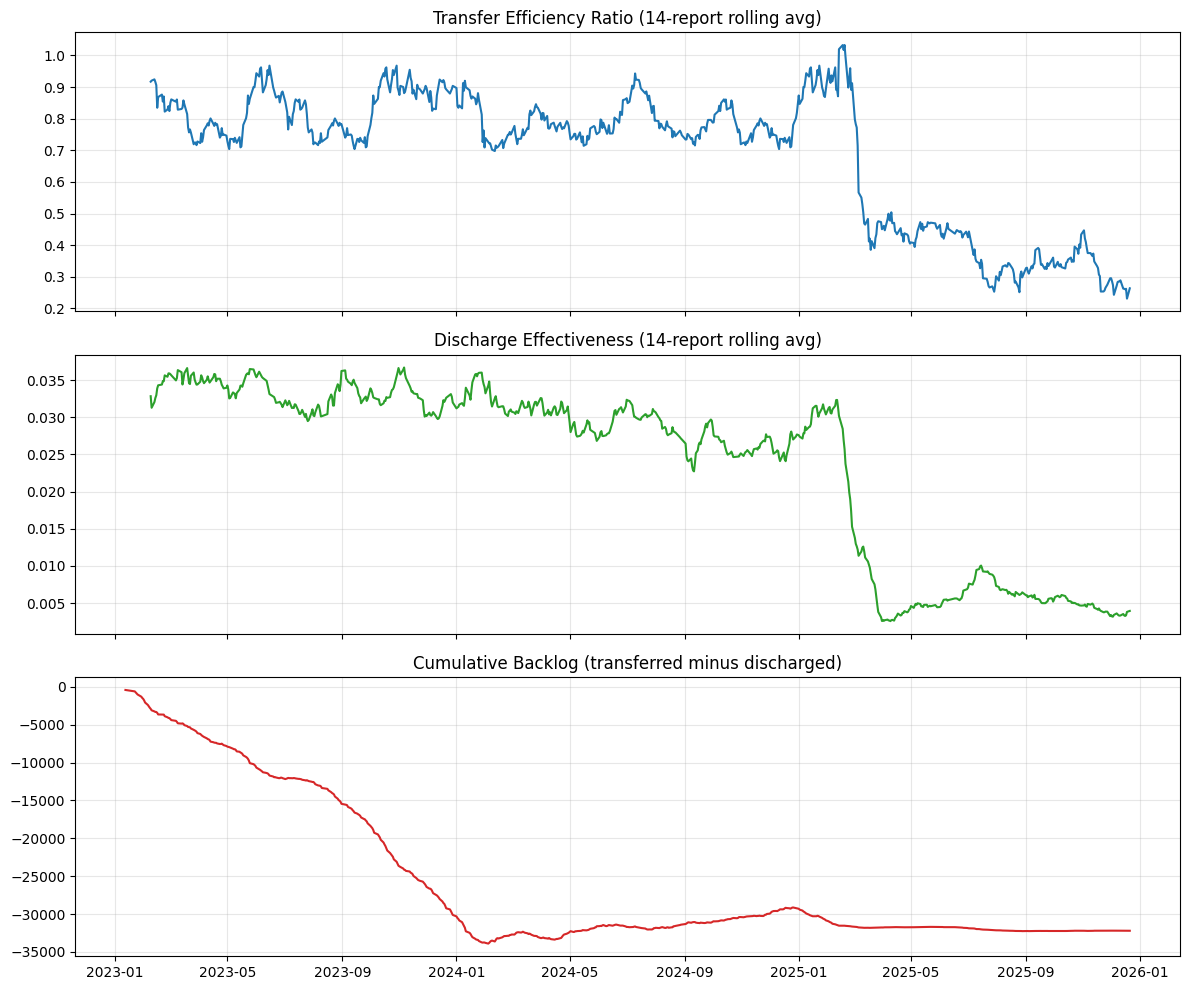

Saved: uac_kpi.csv


In [3]:
# ---------- STEP 2: KPI calculation ----------
import matplotlib.pyplot as plt

# 1. Daily efficiency ratios
df['transfer_eff']   = df['transferred'] / df['cbp_custody']      # Transfers ÷ CBP custody
df['discharge_eff']  = df['discharged']  / df['hhs_care']         # Discharges ÷ HHS care

# 2. Pipeline throughput (exits ÷ entries)
#    System level: discharged to sponsors ÷ newly apprehended
df['throughput'] = np.where(df['apprehended'] > 0, df['discharged'] / df['apprehended'], np.nan)
#    HHS level: discharged ÷ transferred in
df['hhs_throughput'] = np.where(df['transferred'] > 0, df['discharged'] / df['transferred'], np.nan)

# 3. Backlog: inflow minus exits
df['net_flow_hhs']  = df['transferred'] - df['discharged']        # + means HHS load is growing
df['cum_backlog']   = df['net_flow_hhs'].cumsum()
df['hhs_change']    = df['hhs_care'].diff()                       # actual change in HHS load

# 4. Outcome stability: rolling 30-report coefficient of variation of discharges
roll = df['discharged'].rolling(30)
df['discharge_cv'] = roll.std() / roll.mean()

# ---------- OVERALL KPI TABLE ----------
cv_overall = df['discharged'].std() / df['discharged'].mean()
kpi = pd.DataFrame({
    'KPI': ['Transfer Efficiency Ratio (avg)',
            'Discharge Effectiveness Index (avg)',
            'Pipeline Throughput (total discharged ÷ total apprehended)',
            'HHS Throughput (total discharged ÷ total transferred)',
            'Backlog Accumulation Rate (avg net flow per report)',
            'Outcome Stability Score (1 ÷ (1+CV))'],
    'Value': [df['transfer_eff'].mean(),
              df['discharge_eff'].mean(),
              df['discharged'].sum() / df['apprehended'].sum(),
              df['discharged'].sum() / df['transferred'].sum(),
              df['net_flow_hhs'].mean(),
              1 / (1 + cv_overall)]
}).round(4)
print("=== OVERALL KPIs ===")
display(kpi)

# ---------- KPIs BY YEAR ----------
by_year = df.groupby('year').agg(
    transfer_eff=('transfer_eff', 'mean'),
    discharge_eff=('discharge_eff', 'mean'),
    avg_net_flow=('net_flow_hhs', 'mean'),
    avg_hhs_care=('hhs_care', 'mean'),
    total_apprehended=('apprehended', 'sum'),
    total_transferred=('transferred', 'sum'),
    total_discharged=('discharged', 'sum')
).round(4)
by_year['throughput'] = (by_year['total_discharged'] / by_year['total_apprehended']).round(4)
print("\n=== KPIs BY YEAR ===")
display(by_year)

# ---------- QUICK CHARTS ----------
fig, ax = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
ax[0].plot(df['date'], df['transfer_eff'].rolling(14).mean(), color='tab:blue')
ax[0].set_title('Transfer Efficiency Ratio (14-report rolling avg)')
ax[1].plot(df['date'], df['discharge_eff'].rolling(14).mean(), color='tab:green')
ax[1].set_title('Discharge Effectiveness (14-report rolling avg)')
ax[2].plot(df['date'], df['cum_backlog'], color='tab:red')
ax[2].set_title('Cumulative Backlog (transferred minus discharged)')
for a in ax: a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Save
df.to_csv('uac_kpi.csv', index=False)
print("Saved: uac_kpi.csv")

Reports per year:
year
2023    230
2024    251
2025    239
dtype: int64

Sum of (transferred - discharged): -32212
Actual change in HHS care (last - first): -4082
Unexplained gap (likely other HHS inflows): -28130

Structural break near: 2025-03-11


,before,after
transfer_eff,0.8080,0.3671
discharge_eff,0.0304,0.0052
avg_hhs_care,7437.8204,2248.7487
avg_apprehended,124.5728,7.5288
avg_discharged,231.8242,11.6126



Longest periods of growing HHS load (backlog building):


,start,end,reports,growing,avg_change,peak_hhs_care
growing,,,,,,
44,2025-09-01,2025-12-21,77,True,6.5,2484.0
14,2023-07-04,2023-10-05,64,True,81.7,11130.0
42,2025-03-27,2025-06-22,55,True,6.3,2528.0
16,2023-11-13,2023-12-28,32,True,54.8,11516.0
40,2024-12-01,2025-01-01,23,True,19.2,6707.0
20,2024-02-13,2024-03-14,22,True,27.4,8902.0
32,2024-08-20,2024-09-16,18,True,20.2,6448.0
12,2023-04-27,2023-05-18,16,True,22.3,8790.0



Months with biggest build-up:
year_month
2023-01    176.7
2023-08    117.0
2023-07     83.0
2023-11     73.2
2023-09     44.4
Name: hhs_change, dtype: float64

Months with biggest drawdown:
year_month
2024-01   -139.9
2025-01   -115.0
2023-10    -86.9
2025-02    -80.6
2024-03    -69.9
Name: hhs_change, dtype: float64


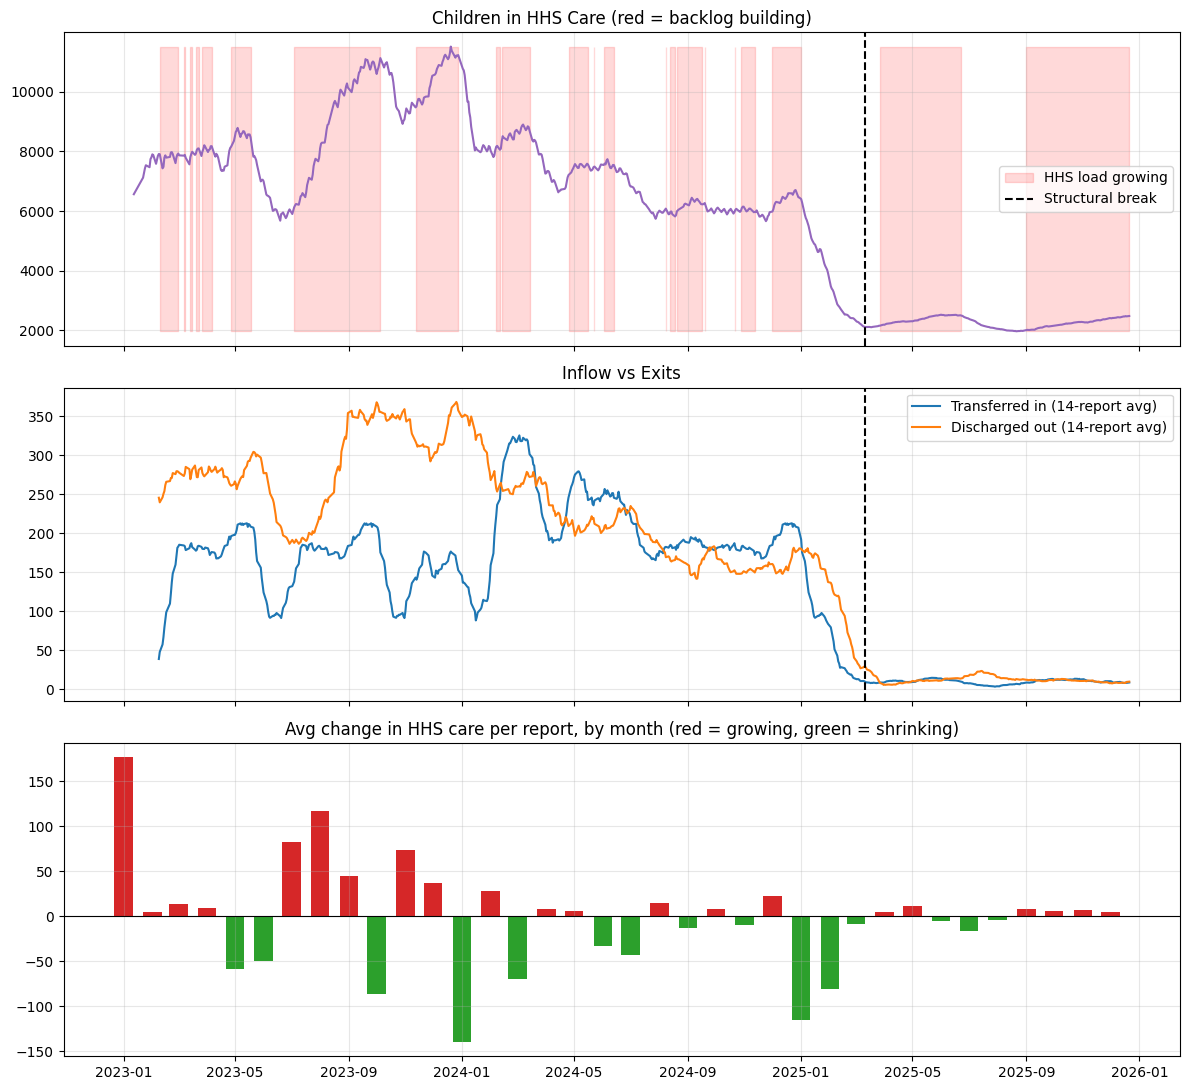

In [4]:
# ---------- STEP 3: Backlog & delay analysis ----------
import matplotlib.pyplot as plt

# 1. Rows per year (are the years comparable?)
print("Reports per year:")
print(df.groupby('year').size())

# 2. Reconcile the two backlog measures
print("\nSum of (transferred - discharged):", int(df['net_flow_hhs'].sum()))
print("Actual change in HHS care (last - first):", int(df['hhs_care'].iloc[-1] - df['hhs_care'].iloc[0]))
print("Unexplained gap (likely other HHS inflows):",
      int(df['net_flow_hhs'].sum() - (df['hhs_care'].iloc[-1] - df['hhs_care'].iloc[0])))

# 3. Find the structural break (largest drop in 14-report transfer efficiency)
df['te14'] = df['transfer_eff'].rolling(14).mean()
df['de14'] = df['discharge_eff'].rolling(14).mean()
drop = df['te14'].diff(10)
bi = drop.idxmin()
break_date = df.loc[bi, 'date']
print("\nStructural break near:", break_date.date())
before = df[df['date'] < break_date]
after  = df[df['date'] >= break_date]
cmp = pd.DataFrame({
    'before': [before['transfer_eff'].mean(), before['discharge_eff'].mean(),
               before['hhs_care'].mean(), before['apprehended'].mean(), before['discharged'].mean()],
    'after':  [after['transfer_eff'].mean(), after['discharge_eff'].mean(),
               after['hhs_care'].mean(), after['apprehended'].mean(), after['discharged'].mean()]
}, index=['transfer_eff', 'discharge_eff', 'avg_hhs_care', 'avg_apprehended', 'avg_discharged']).round(4)
display(cmp)

# 4. Sustained imbalance: periods where HHS load kept growing (14-report avg change > 0)
df['hhs_change_14'] = df['hhs_change'].rolling(14).mean()
df['growing'] = df['hhs_change_14'] > 0
grp = (df['growing'] != df['growing'].shift()).cumsum()
runs = df.groupby(grp).agg(start=('date', 'first'), end=('date', 'last'),
                           reports=('date', 'count'), growing=('growing', 'first'),
                           avg_change=('hhs_change', 'mean'), peak_hhs_care=('hhs_care', 'max'))
growth_runs = runs[(runs['growing']) & (runs['reports'] >= 10)].sort_values('reports', ascending=False)
print("\nLongest periods of growing HHS load (backlog building):")
display(growth_runs.head(8).round(1))

# 5. Monthly average change in HHS load
monthly = df.groupby('year_month')['hhs_change'].mean()
print("\nMonths with biggest build-up:")
print(monthly.nlargest(5).round(1))
print("\nMonths with biggest drawdown:")
print(monthly.nsmallest(5).round(1))

# 6. Charts
fig, ax = plt.subplots(3, 1, figsize=(12, 11), sharex=True)

ax[0].plot(df['date'], df['hhs_care'], color='tab:purple')
ax[0].fill_between(df['date'], df['hhs_care'].min(), df['hhs_care'].max(),
                   where=df['growing'], color='red', alpha=0.15, label='HHS load growing')
ax[0].axvline(break_date, color='black', linestyle='--', label='Structural break')
ax[0].set_title('Children in HHS Care (red = backlog building)')
ax[0].legend()

ax[1].plot(df['date'], df['transferred'].rolling(14).mean(), label='Transferred in (14-report avg)')
ax[1].plot(df['date'], df['discharged'].rolling(14).mean(), label='Discharged out (14-report avg)')
ax[1].axvline(break_date, color='black', linestyle='--')
ax[1].set_title('Inflow vs Exits')
ax[1].legend()

colors = ['tab:red' if v > 0 else 'tab:green' for v in monthly.values]
ax[2].bar(pd.to_datetime(monthly.index), monthly.values, width=20, color=colors)
ax[2].axhline(0, color='black', linewidth=0.8)
ax[2].set_title('Avg change in HHS care per report, by month (red = growing, green = shrinking)')

for a in ax: a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

df.to_csv('uac_kpi.csv', index=False)

=== SUNDAY vs MON-THU ===


apprehended  transferred  discharged  transfer_eff  \
period       day_type                                                       
After break  Mon-Thu         7.773        9.558      12.675         0.360   
             Sunday          6.472        9.139       7.139         0.399   
Before break Mon-Thu       125.760      170.601     220.772         0.806   
             Sunday        119.553      176.372     282.351         0.815   

                       discharge_eff  discharged_per_day  
period       day_type                                     
After break  Mon-Thu           0.006              12.224  
             Sunday            0.003               2.375  
Before break Mon-Thu           0.029             213.346  
             Sunday            0.038              92.977


Best 5 months (avg discharges per report):


,avg_discharged,avg_transferred,avg_discharge_eff,reports,mom_pct
year_month,,,,,
2023-12,358.1,163.4,0.0,19,19.5
2023-10,348.1,93.1,0.0,22,1.0
2023-09,344.5,209.0,0.0,19,6.5
2023-08,323.5,179.4,0.0,20,54.2
2023-11,299.6,159.9,0.0,20,-13.9


Worst 5 months:


,avg_discharged,avg_transferred,avg_discharge_eff,reports,mom_pct
year_month,,,,,
2025-11,8.4,9.6,0.0,19,-27.4
2025-04,8.8,10.0,0.0,23,-37.2
2025-12,9.6,8.3,0.0,15,14.7
2025-09,10.8,11.8,0.0,22,-15.2
2025-05,11.4,14.0,0.0,18,29.0


Biggest month-over-month drops (%):


,mom_pct
year_month,
2025-03,-77.0
2025-02,-59.7
2025-04,-37.2
2025-08,-32.7
2023-06,-29.2



Prolonged stagnation periods (20+ reports):


,start,end,reports,stagnant,avg_hhs_care
stagnant,,,,,
8,2025-10-01,2025-12-21,55,True,2322.0
2,2025-03-27,2025-05-18,38,True,2296.0
6,2025-08-04,2025-09-25,38,True,2035.0


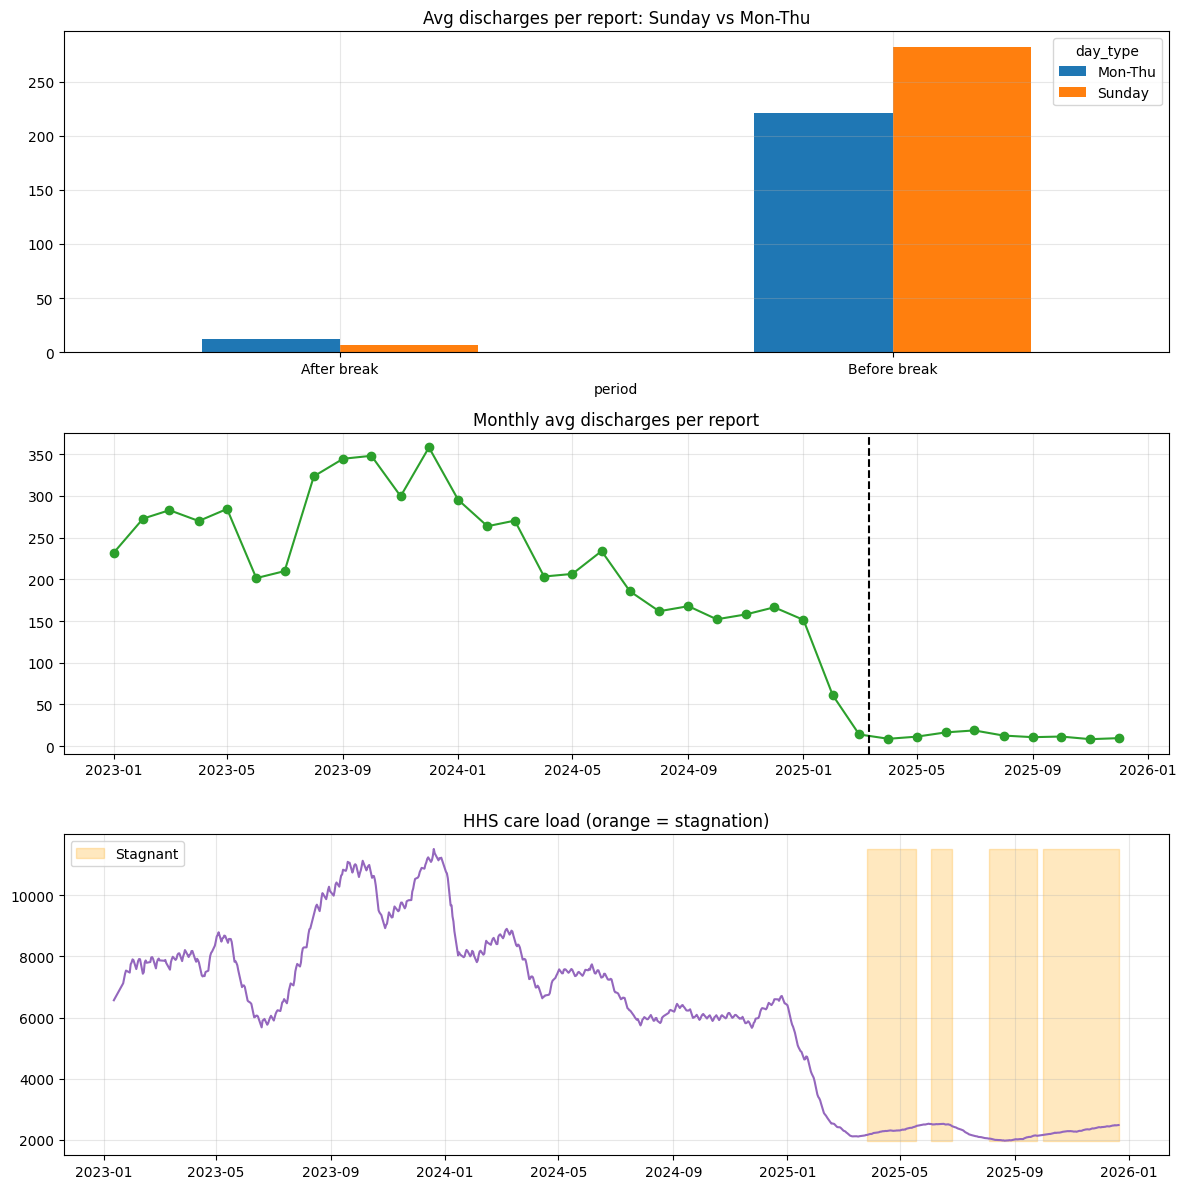

In [5]:
# ---------- STEP 4: Temporal & pattern analysis ----------
import matplotlib.pyplot as plt

# 1. Labels (break_date comes from Step 3)
df['day_type'] = np.where(df['weekday'] == 'Sunday', 'Sunday',
                  np.where(df['weekday'].isin(['Monday','Tuesday','Wednesday','Thursday']),
                           'Mon-Thu', 'Fri/other'))
df['period'] = np.where(df['date'] < break_date, 'Before break', 'After break')
df['discharged_per_day']  = df['discharged'] / df['gap_days']
df['hhs_change_per_day']  = df['hhs_change'] / df['gap_days']

# 2. Sunday vs Mon-Thu (Friday rows excluded, only 2 exist)
wd = df[df['day_type'] != 'Fri/other']
tbl = wd.groupby(['period', 'day_type'])[['apprehended', 'transferred', 'discharged',
                                          'transfer_eff', 'discharge_eff',
                                          'discharged_per_day']].mean().round(3)
print("=== SUNDAY vs MON-THU ===")
display(tbl)

# 3. Monthly placement trend
m = df.groupby('year_month').agg(avg_discharged=('discharged', 'mean'),
                                 avg_transferred=('transferred', 'mean'),
                                 avg_discharge_eff=('discharge_eff', 'mean'),
                                 reports=('date', 'count'))
m['mom_pct'] = (m['avg_discharged'].pct_change() * 100).round(1)
print("\nBest 5 months (avg discharges per report):")
display(m.nlargest(5, 'avg_discharged').round(1))
print("Worst 5 months:")
display(m.nsmallest(5, 'avg_discharged').round(1))
print("Biggest month-over-month drops (%):")
display(m['mom_pct'].nsmallest(5))

# 4. Stagnation: HHS load barely changing (avg |change| < 0.5% of load, 14-report window)
df['stagnant'] = (df['hhs_change'].abs().rolling(14).mean() / df['hhs_care']) < 0.005
g = (df['stagnant'] != df['stagnant'].shift()).cumsum()
st = df.groupby(g).agg(start=('date', 'first'), end=('date', 'last'),
                       reports=('date', 'count'), stagnant=('stagnant', 'first'),
                       avg_hhs_care=('hhs_care', 'mean'))
st = st[st['stagnant'] & (st['reports'] >= 20)].sort_values('reports', ascending=False)
print("\nProlonged stagnation periods (20+ reports):")
display(st.round(0))

# 5. Charts
fig, ax = plt.subplots(3, 1, figsize=(12, 12))

tbl['discharged'].unstack().plot(kind='bar', ax=ax[0], rot=0)
ax[0].set_title('Avg discharges per report: Sunday vs Mon-Thu')

ax[1].plot(pd.to_datetime(m.index), m['avg_discharged'], marker='o', color='tab:green')
ax[1].axvline(break_date, color='black', linestyle='--')
ax[1].set_title('Monthly avg discharges per report')

ax[2].plot(df['date'], df['hhs_care'], color='tab:purple')
ax[2].fill_between(df['date'], df['hhs_care'].min(), df['hhs_care'].max(),
                   where=df['stagnant'], color='orange', alpha=0.25, label='Stagnant')
ax[2].set_title('HHS care load (orange = stagnation)')
ax[2].legend()

for a in ax: a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

df.to_csv('uac_kpi.csv', index=False)

=== Discharge stability: before vs after break ===


,mean,std,CV,stability_score
period,,,,
After break,11.613,6.213,0.535,0.651
Before break,231.824,92.816,0.400,0.714


=== Discharge stability by year ===


,mean,std,CV,stability_score
year,,,,
2023,288.017,80.041,0.278,0.783
2024,205.932,67.335,0.327,0.754
2025,28.954,45.217,1.562,0.390



=== Sudden drops in discharges (worst first) ===


,start,end,reports,is_drop,worst_drop_pct
sudden_drop,,,,,
8,2025-02-17,2025-02-27,9,True,-73.8
6,2025-02-11,2025-02-12,2,True,-36.9
2,2024-04-09,2024-04-09,1,True,-31.8
4,2025-01-28,2025-01-29,2,True,-30.6



Median implied days in care by period:
period
After break     194.9
Before break     32.2
Name: implied_days, dtype: float64


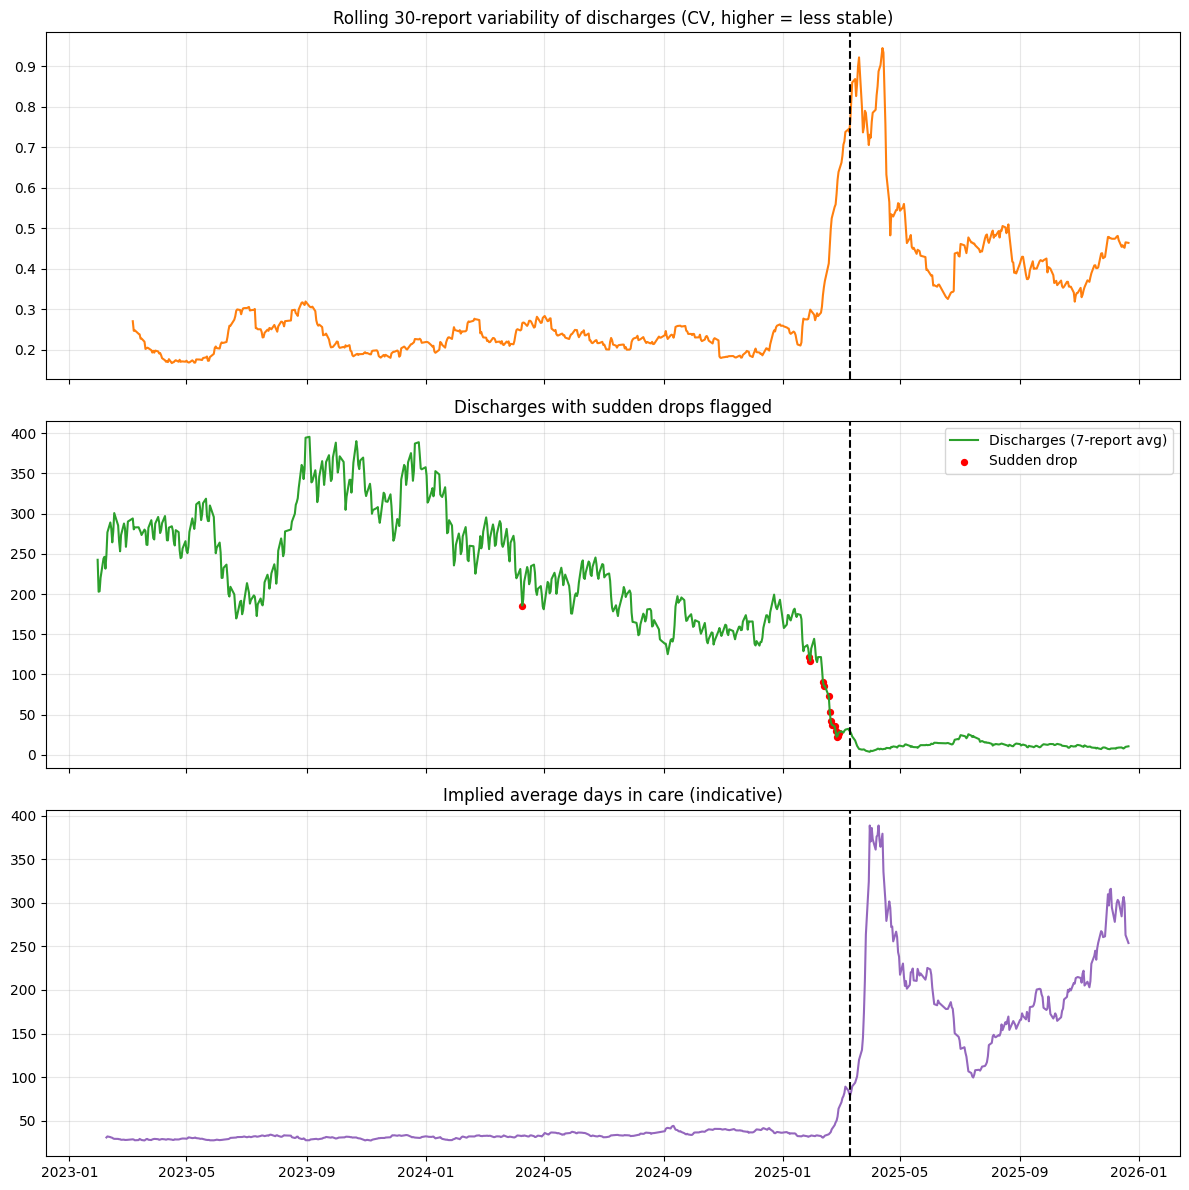

In [6]:
# ---------- STEP 5: Outcome stability analysis ----------
import matplotlib.pyplot as plt

# 1. Variability of discharges: before vs after break, and by year
def stability(x):
    cv = x.std() / x.mean()
    return pd.Series({'mean': x.mean(), 'std': x.std(), 'CV': cv,
                      'stability_score': 1 / (1 + cv)})

print("=== Discharge stability: before vs after break ===")
display(df.groupby('period')['discharged'].apply(stability).unstack().round(3))
print("=== Discharge stability by year ===")
display(df.groupby('year')['discharged'].apply(stability).unstack().round(3))

# 2. Sudden drops: 7-report avg falls >30% vs the previous 7 reports (only when level >= 50)
r7 = df['discharged'].rolling(7).mean()
df['drop_pct'] = (r7 / r7.shift(7) - 1) * 100
df['sudden_drop'] = (df['drop_pct'] < -30) & (r7.shift(7) >= 50)

g = (df['sudden_drop'] != df['sudden_drop'].shift()).cumsum()
ev = df.groupby(g).agg(start=('date', 'first'), end=('date', 'last'),
                       reports=('date', 'count'), is_drop=('sudden_drop', 'first'),
                       worst_drop_pct=('drop_pct', 'min'))
ev = ev[ev['is_drop']].sort_values('worst_drop_pct')
print("\n=== Sudden drops in discharges (worst first) ===")
display(ev.head(10).round(1))

# 3. Implied average days in care (stock ÷ daily exits), an indicative estimate
df['implied_days'] = df['hhs_care'].rolling(14).mean() / df['discharged'].rolling(14).mean().replace(0, np.nan)
print("\nMedian implied days in care by period:")
print(df.groupby('period')['implied_days'].median().round(1))

# 4. Charts
fig, ax = plt.subplots(3, 1, figsize=(12, 12), sharex=True)

ax[0].plot(df['date'], df['discharge_cv'], color='tab:orange')
ax[0].set_title('Rolling 30-report variability of discharges (CV, higher = less stable)')

ax[1].plot(df['date'], r7, color='tab:green', label='Discharges (7-report avg)')
ax[1].scatter(df.loc[df['sudden_drop'], 'date'], r7[df['sudden_drop']],
              color='red', s=18, label='Sudden drop')
ax[1].set_title('Discharges with sudden drops flagged')
ax[1].legend()

ax[2].plot(df['date'], df['implied_days'], color='tab:purple')
ax[2].set_title('Implied average days in care (indicative)')

for a in ax:
    a.axvline(break_date, color='black', linestyle='--')
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

df.to_csv('uac_kpi.csv', index=False)

In [7]:
!pip install -q streamlit

In [8]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go

st.set_page_config(page_title="Care Transition Efficiency Dashboard", layout="wide")

@st.cache_data
def load():
    d = pd.read_csv("uac_clean.csv", parse_dates=["date"])
    d = d[["date", "apprehended", "cbp_custody", "transferred", "hhs_care", "discharged"]]
    d = d.sort_values("date").reset_index(drop=True)
    d["transfer_eff"] = d["transferred"] / d["cbp_custody"]
    d["discharge_eff"] = d["discharged"] / d["hhs_care"]
    d["hhs_change"] = d["hhs_care"].diff()
    d["month"] = d["date"].dt.to_period("M").astype(str)
    return d

df_all = load()

# ---------------- Sidebar ----------------
st.sidebar.header("Filters")
min_d, max_d = df_all["date"].min().date(), df_all["date"].max().date()
rng = st.sidebar.date_input("Date range", value=(min_d, max_d), min_value=min_d, max_value=max_d)
if len(rng) != 2:
    st.info("Select both a start date and an end date.")
    st.stop()
start, end = rng

metrics = st.sidebar.multiselect("Ratio metrics to show",
                                 ["Transfer Efficiency", "Discharge Effectiveness"],
                                 default=["Transfer Efficiency", "Discharge Effectiveness"])
window = st.sidebar.slider("Rolling window (reports)", 1, 30, 14)

st.sidebar.subheader("Alert thresholds")
t_te = st.sidebar.slider("Min transfer efficiency", 0.0, 1.0, 0.5, 0.05)
t_de = st.sidebar.slider("Min discharge effectiveness", 0.0, 0.05, 0.02, 0.005)
t_bl = st.sidebar.slider("Max avg HHS load growth per report", 0, 100, 20)

df = df_all[(df_all["date"].dt.date >= start) & (df_all["date"].dt.date <= end)].copy()
if len(df) < 15:
    st.warning("Please select a longer date range (at least 15 reports).")
    st.stop()

# ---------------- Title + KPIs ----------------
st.title("Care Transition Efficiency & Placement Outcome Analytics")
st.caption("HHS Unaccompanied Alien Children Program | CBP custody -> HHS care -> sponsor placement")

cv = df["discharged"].std() / df["discharged"].mean()
throughput = df["discharged"].sum() / max(df["apprehended"].sum(), 1)

k1, k2, k3, k4, k5 = st.columns(5)
k1.metric("Transfer Efficiency", f"{df['transfer_eff'].mean():.2f}")
k2.metric("Discharge Effectiveness", f"{df['discharge_eff'].mean():.3f}")
k3.metric("Pipeline Throughput", f"{throughput:.2f}")
k4.metric("Backlog Rate (avg HHS change/report)", f"{df['hhs_change'].mean():.1f}")
k5.metric("Outcome Stability Score", f"{1 / (1 + cv):.2f}")

# ---------------- Alerts (latest window in range) ----------------
st.subheader(f"Alerts (last {window} reports in selected range)")
recent = df.tail(window)
r_te, r_de, r_bl = recent["transfer_eff"].mean(), recent["discharge_eff"].mean(), recent["hhs_change"].mean()
a1, a2, a3 = st.columns(3)
(a1.error if r_te < t_te else a1.success)(f"Transfer efficiency {r_te:.2f} (min {t_te:.2f})")
(a2.error if r_de < t_de else a2.success)(f"Discharge effectiveness {r_de:.3f} (min {t_de:.3f})")
(a3.error if r_bl > t_bl else a3.success)(f"HHS load change {r_bl:.1f}/report (max {t_bl})")

# ---------------- Tabs ----------------
tab1, tab2, tab3, tab4 = st.tabs(["Pipeline Flow", "Efficiency", "Bottlenecks", "Outcome Trends"])

with tab1:
    c1, c2 = st.columns(2)
    stage = pd.DataFrame({
        "Stage": ["Apprehended (CBP intake)", "Transferred to HHS", "Discharged to sponsors"],
        "Children": [df["apprehended"].sum(), df["transferred"].sum(), df["discharged"].sum()]})
    c1.plotly_chart(px.bar(stage, x="Stage", y="Children", color="Stage",
                           title="Pipeline stage volumes (total in range)"))
    load_fig = go.Figure()
    load_fig.add_trace(go.Scatter(x=df["date"], y=df["cbp_custody"], name="In CBP custody"))
    load_fig.add_trace(go.Scatter(x=df["date"], y=df["hhs_care"], name="In HHS care", yaxis="y2"))
    load_fig.update_layout(title="Care load by stage", yaxis=dict(title="CBP custody"),
                           yaxis2=dict(title="HHS care", overlaying="y", side="right"))
    c2.plotly_chart(load_fig)

with tab2:
    cols = st.columns(len(metrics)) if metrics else []
    if "Transfer Efficiency" in metrics:
        f = go.Figure(go.Scatter(x=df["date"], y=df["transfer_eff"].rolling(window).mean(), name="Transfer Efficiency"))
        f.add_hline(y=t_te, line_dash="dash", line_color="red", annotation_text="threshold")
        f.update_layout(title="Transfer Efficiency Ratio (transfers / CBP custody)")
        cols[metrics.index("Transfer Efficiency")].plotly_chart(f)
    if "Discharge Effectiveness" in metrics:
        f = go.Figure(go.Scatter(x=df["date"], y=df["discharge_eff"].rolling(window).mean(),
                                 name="Discharge Effectiveness", line=dict(color="green")))
        f.add_hline(y=t_de, line_dash="dash", line_color="red", annotation_text="threshold")
        f.update_layout(title="Discharge Effectiveness (discharges / HHS care)")
        cols[metrics.index("Discharge Effectiveness")].plotly_chart(f)
    if not metrics:
        st.info("Select at least one metric in the sidebar.")

with tab3:
    b1, b2 = st.columns(2)
    flow = go.Figure()
    flow.add_trace(go.Scatter(x=df["date"], y=df["transferred"].rolling(window).mean(), name="Transferred in"))
    flow.add_trace(go.Scatter(x=df["date"], y=df["discharged"].rolling(window).mean(), name="Discharged out"))
    flow.update_layout(title="Inflow vs exits (rolling average)")
    b1.plotly_chart(flow)

    monthly = df.groupby("month")["hhs_change"].mean().reset_index()
    monthly["direction"] = np.where(monthly["hhs_change"] > 0, "Growing", "Shrinking")
    b2.plotly_chart(px.bar(monthly, x="month", y="hhs_change", color="direction",
                           color_discrete_map={"Growing": "crimson", "Shrinking": "seagreen"},
                           title="Avg change in HHS care per report, by month"))
    hot = monthly[monthly["hhs_change"] > t_bl]
    if len(hot):
        st.warning("Months above the backlog threshold: " + ", ".join(hot["month"]))
    else:
        st.success("No month exceeds the backlog threshold in this range.")

with tab4:
    o1, o2 = st.columns(2)
    r7 = df["discharged"].rolling(7).mean()
    prev = r7.shift(7)
    flag = ((r7 / prev - 1) * 100 < -30) & (prev >= 50)
    f = go.Figure(go.Scatter(x=df["date"], y=r7, name="Discharges (7-report avg)", line=dict(color="green")))
    f.add_trace(go.Scatter(x=df.loc[flag, "date"], y=r7[flag], mode="markers",
                           marker=dict(color="red", size=7), name="Sudden drop"))
    f.update_layout(title="Discharges with sudden drops flagged")
    o1.plotly_chart(f)

    cvroll = df["discharged"].rolling(30).std() / df["discharged"].rolling(30).mean()
    o2.plotly_chart(px.line(x=df["date"], y=cvroll,
                            labels={"x": "date", "y": "CV"},
                            title="Variability of discharges (30-report CV, higher = less stable)"))
    st.caption(f"{int(flag.sum())} reports flagged as sudden drops in this range.")

st.caption("Note: HHS reports mostly Mon-Thu and Sunday (no Saturday, almost no Friday). "
           "Efficiency ratios are used for comparisons because they are unaffected by gaps.")

Writing app.py


In [11]:
!pkill -f streamlit
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared
!nohup streamlit run app.py --server.port 8501 --server.enableCORS false --server.enableXsrfProtection false > logs.txt 2>&1 &
import time
time.sleep(6)
!./cloudflared tunnel --url http://localhost:8501

2026-11-04T15:59:57Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-04T15:59:57Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-04T16:00:00Z INF +--------------------------------------------------------------------------------------------+
2026-11-04T16:00:00Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-04T16:00:00Z INF |  https://moon-lemon-illustration-table.trycloudflare.c

In [12]:
import matplotlib.pyplot as plt, zipfile
from google.colab import files

def save(fig, name):
    fig.tight_layout(); fig.savefig(name, dpi=200); plt.close(fig)

# Figure 1: efficiency ratios
fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
ax[0].plot(df['date'], df['te14']); ax[0].set_title('Transfer Efficiency Ratio (14-report rolling avg)')
ax[1].plot(df['date'], df['de14'], color='green'); ax[1].set_title('Discharge Effectiveness (14-report rolling avg)')
for a in ax: a.axvline(break_date, color='black', linestyle='--'); a.grid(alpha=0.3)
save(fig, 'fig1_efficiency.png')

# Figure 2: HHS care with backlog-building periods
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(df['date'], df['hhs_care'], color='tab:purple')
ax.fill_between(df['date'], df['hhs_care'].min(), df['hhs_care'].max(), where=df['growing'], color='red', alpha=0.15, label='HHS load growing')
ax.axvline(break_date, color='black', linestyle='--', label='Structural break')
ax.set_title('Children in HHS care'); ax.legend(); ax.grid(alpha=0.3)
save(fig, 'fig2_hhs_care.png')

# Figure 3: inflow vs exits
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(df['date'], df['transferred'].rolling(14).mean(), label='Transferred in')
ax.plot(df['date'], df['discharged'].rolling(14).mean(), label='Discharged out')
ax.axvline(break_date, color='black', linestyle='--'); ax.set_title('Inflow vs exits (14-report avg)'); ax.legend(); ax.grid(alpha=0.3)
save(fig, 'fig3_inflow_exits.png')

# Figure 4: monthly discharges + Sunday vs Mon-Thu
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(pd.to_datetime(m.index), m['avg_discharged'], marker='o', color='tab:green')
ax[0].axvline(break_date, color='black', linestyle='--'); ax[0].set_title('Monthly avg discharges per report')
tbl['discharged'].unstack().plot(kind='bar', ax=ax[1], rot=0); ax[1].set_title('Avg discharges: Sunday vs Mon-Thu')
for a in ax: a.grid(alpha=0.3)
save(fig, 'fig4_monthly_sunday.png')

# Figure 5: stability and sudden drops
fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
ax[0].plot(df['date'], df['discharge_cv'], color='tab:orange'); ax[0].set_title('Rolling 30-report variability of discharges (CV)')
ax[1].plot(df['date'], r7, color='tab:green'); ax[1].scatter(df.loc[df['sudden_drop'], 'date'], r7[df['sudden_drop']], color='red', s=18)
ax[1].set_title('Discharges (7-report avg) with sudden drops')
for a in ax: a.axvline(break_date, color='black', linestyle='--'); a.grid(alpha=0.3)
save(fig, 'fig5_stability.png')

with zipfile.ZipFile('paper_figures.zip', 'w') as z:
    for f in ['fig1_efficiency.png','fig2_hhs_care.png','fig3_inflow_exits.png','fig4_monthly_sunday.png','fig5_stability.png']:
        z.write(f)
files.download('paper_figures.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>